### Entscheidungsbäume (Decision Trees)

[Video](https://youtu.be/nEBac-B231E) - [Video2](https://youtu.be/Ev3geu5DZxU) - [In Colab öffnen](https://colab.research.google.com/github/ktheu/InfoKursN/blob/main/decisionTrees/inhalte/decision_trees.ipynb)

Das Notebook braucht die Pakete `pandas`, `matplotlib` und `scikit-learn`. In Google Colab sind sie schon installiert.

**Maschinelles Lernen** heißt: Ein Programm lernt eine Regel aus Beispielen, statt dass ein Mensch sie
programmiert. Bei einer **Klassifikation** gibt es Beispiele mit **Merkmalen** (z.B. Wetter und Wind) und einer
bekannten **Klasse** (z.B. ob gespielt wurde). Daraus soll ein Modell entstehen, das für neue Fälle die Klasse
vorhersagt.

Ein **Entscheidungsbaum** stellt nacheinander Ja/Nein-Fragen zu den Merkmalen. An den Blättern steht die
vorhergesagte Klasse.

<img src="baum_wetter.png" width="330">

Wie findet man die Fragen? Man wählt immer die Frage, die die Beispiele am besten nach Klassen trennt. Dazu braucht
man ein Maß dafür, wie gemischt eine Gruppe ist.

### Gini Impurity

Der **Gini Impurity Index** (Gini-Unreinheit) misst die Vielfalt in einer Sammlung von Objekten. Er ist die
Wahrscheinlichkeit, bei zweimaligem Ziehen mit Zurücklegen zwei verschiedenartige Objekte zu ziehen.

Beispiel: Eine Urne enthält 7 blaue und 3 rote Kugeln. Zwei gleichfarbige Kugeln zieht man mit der Wahrscheinlichkeit
$0.7^2 + 0.3^2$, verschiedenfarbige mit der Gegenwahrscheinlichkeit.

In [1]:
zwei_blaue = (7 / 10) ** 2
zwei_rote = (3 / 10) ** 2
gini = 1 - (zwei_blaue + zwei_rote)
round(gini, 4)

0.42

Sind $p_1, p_2, \dots, p_k$ die Anteile der Klassen, dann ist

$$\text{Gini} = 1 - p_1^2 - p_2^2 - \dots - p_k^2$$

- Gini $= 0$: Die Gruppe ist **rein**, es gibt nur eine Klasse.
- Bei zwei Klassen ist Gini höchstens $0.5$, das ist der Fall, wenn beide gleich häufig sind.

Wir schreiben J für Ja und N für Nein:

In [2]:
def gini(klassen):
    '''Gini Impurity einer Liste von Klassen'''
    n = len(klassen)
    return 1 - sum((klassen.count(k) / n) ** 2 for k in set(klassen))

for gruppe in ['JJNN', 'JN', 'NNN', 'NJJJ', 'NJJ']:
    print(f'{gruppe:5} {gini(list(gruppe)):.3f}')

JJNN  0.500
JN    0.500
NNN   0.000
NJJJ  0.375
NJJ   0.444


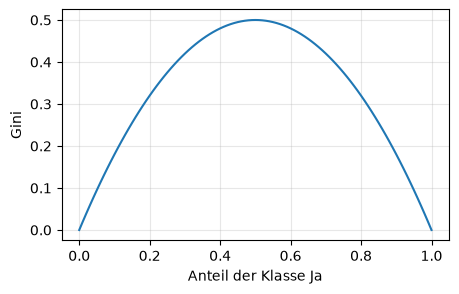

In [3]:
import matplotlib.pyplot as plt

p = [i / 100 for i in range(101)]
plt.figure(figsize=(5, 3))
plt.plot(p, [1 - x ** 2 - (1 - x) ** 2 for x in p])
plt.xlabel('Anteil der Klasse Ja')
plt.ylabel('Gini')
plt.grid(alpha=0.3)
plt.show()

### Die beste Frage finden

Eine Frage teilt die Beispiele in eine Ja-Gruppe und eine Nein-Gruppe. Bewertet wird die Frage mit dem
**gewichteten Gini** der beiden Gruppen: Jede Gruppe zählt mit ihrem Anteil an allen Beispielen. Je kleiner, desto
besser trennt die Frage.

$$\text{Gini}_\text{Split} = \frac{n_\text{ja}}{n} \cdot \text{Gini}(\text{ja}) + \frac{n_\text{nein}}{n} \cdot
\text{Gini}(\text{nein})$$

#### Beispiel 1: Wetter

An sechs Tagen wurde notiert, ob draußen gespielt wurde:

In [4]:
import pandas as pd

wetter = pd.DataFrame({
    'Wetter': ['sonnig', 'sonnig', 'bewölkt', 'bewölkt', 'regen', 'regen'],
    'Wind': ['schwach', 'stark', 'schwach', 'stark', 'schwach', 'stark'],
    'Spielen': ['Ja', 'Nein', 'Ja', 'Ja', 'Nein', 'Nein'],
})
wetter

,Wetter,Wind,Spielen
0,sonnig,schwach,Ja
1,sonnig,stark,Nein
2,bewölkt,schwach,Ja
3,bewölkt,stark,Ja
4,regen,schwach,Nein
5,regen,stark,Nein


Die Frage *Wetter sonnig?* teilt in sonnig (Ja, Nein) und den Rest (Ja, Ja, Nein, Nein):

$$\tfrac{2}{6} \cdot 0.5 + \tfrac{4}{6} \cdot 0.5 = 0.5$$

Diese Frage hilft also gar nicht, beide Gruppen sind so gemischt wie vorher. Die Frage *Wetter bewölkt?* ergibt
bewölkt (Ja, Ja) und den Rest (Ja, Nein, Nein, Nein):

$$\tfrac{2}{6} \cdot 0 + \tfrac{4}{6} \cdot \left(1 - \left(\tfrac{1}{4}\right)^2 - \left(\tfrac{3}{4}\right)^2\right)
= \tfrac{4}{6} \cdot 0.375 = 0.25$$

In Python probieren wir alle Fragen aus. Bei einem Merkmal mit Texten fragen wir nach jedem Wert, bei nur zwei Werten
reicht eine Frage.

In [5]:
def gini_split(ja, nein):
    n = len(ja) + len(nein)
    return len(ja) / n * gini(ja) + len(nein) / n * gini(nein)

def fragen(df, ziel):
    '''alle Ja/Nein-Fragen als (Merkmal, Vergleich, Wert)'''
    ergebnis = []
    for m in df.columns:
        if m == ziel:
            continue
        werte = sorted(df[m].unique())
        if pd.api.types.is_numeric_dtype(df[m]):
            for a, b in zip(werte, werte[1:]):
                ergebnis.append((m, '<', (a + b) / 2))
        elif len(werte) == 2:
            ergebnis.append((m, '==', werte[0]))
        elif len(werte) > 2:
            for w in werte:
                ergebnis.append((m, '==', w))
    return ergebnis

def antwort(df, frage):
    '''True/False für jede Zeile'''
    m, vergleich, wert = frage
    return df[m] == wert if vergleich == '==' else df[m] < wert

def bewertungen(df, ziel):
    for frage in fragen(df, ziel):
        ja = list(df[antwort(df, frage)][ziel])
        nein = list(df[~antwort(df, frage)][ziel])
        print(f'{frage[0]} {frage[1]} {frage[2]}:'.ljust(26), f'{gini_split(ja, nein):.3f}')

bewertungen(wetter, 'Spielen')

Wetter == bewölkt:         0.250
Wetter == regen:           0.250
Wetter == sonnig:          0.500
Wind == schwach:           0.444


*bewölkt* und *Regen* sind gleich gut (beide $0.25$), wir nehmen die erste. Bei *bewölkt* ist die Ja-Gruppe schon
rein: Dort wird immer gespielt. In der Nein-Gruppe geht es mit denselben Regeln weiter:

In [6]:
rest = wetter[wetter['Wetter'] != 'bewölkt']
bewertungen(rest, 'Spielen')

Wetter == regen:           0.250
Wind == schwach:           0.250


Wieder sind beide Fragen gleich gut. Mit *Regen* ist die Ja-Gruppe rein (nie gespielt), übrig bleiben die beiden
sonnigen Tage, und die trennt die Frage nach dem Wind. So entsteht der Baum vom Anfang.

### Der Baum als rekursiver Algorithmus

Das Verfahren ist rekursiv:

- Ist die Gruppe rein (oder gibt es keine Frage mehr), wird sie ein **Blatt**. Es sagt die häufigste Klasse voraus.
- Sonst nimm die Frage mit dem kleinsten gewichteten Gini, teile die Gruppe und baue für beide Teile wieder einen
  Baum.

Man nennt das Verfahren **gierig** (greedy): Es nimmt in jedem Schritt die gerade beste Frage und prüft nicht, ob
eine andere Reihenfolge insgesamt einen kleineren Baum ergeben würde.

In [7]:
def baue_baum(df, ziel):
    klassen = list(df[ziel])
    beste, bester_wert = None, gini(klassen)
    for frage in fragen(df, ziel):
        ja = list(df[antwort(df, frage)][ziel])
        nein = list(df[~antwort(df, frage)][ziel])
        if ja and nein and gini_split(ja, nein) < bester_wert:
            beste, bester_wert = frage, gini_split(ja, nein)
    if beste is None:
        haeufigste = max(set(klassen), key=klassen.count)
        return {'klasse': haeufigste, 'anzahl': len(klassen)}
    maske = antwort(df, beste)
    return {'frage': beste, 'ja': baue_baum(df[maske], ziel), 'nein': baue_baum(df[~maske], ziel)}

def zeige(baum, einrueckung=''):
    if 'klasse' in baum:
        print(f"{baum['klasse']} ({baum['anzahl']})")
        return
    m, vergleich, wert = baum['frage']
    print(f'{m} {vergleich} {wert}?')
    print(einrueckung + '  ja:   ', end='')
    zeige(baum['ja'], einrueckung + '        ')
    print(einrueckung + '  nein: ', end='')
    zeige(baum['nein'], einrueckung + '        ')

baum = baue_baum(wetter, 'Spielen')
zeige(baum)

Wetter == bewölkt?
  ja:   Ja (2)
  nein: Wetter == regen?
          ja:   Nein (2)
          nein: Wind == schwach?
                  ja:   Ja (1)
                  nein: Nein (1)


In Klammern steht, wie viele Beispiele im Blatt landen. Zum Vorhersagen läuft man von oben die Fragen entlang:

In [8]:
def vorhersage(baum, zeile):
    while 'klasse' not in baum:
        m, vergleich, wert = baum['frage']
        ja = zeile[m] == wert if vergleich == '==' else zeile[m] < wert
        baum = baum['ja'] if ja else baum['nein']
    return baum['klasse']

vorhersage(baum, {'Wetter': 'sonnig', 'Wind': 'schwach'})

'Ja'

#### Beispiel 2: Zahlen als Merkmal

Bei einem Merkmal mit Zahlen wie dem Alter fragt man *Alter < s?*. Als Schwellen $s$ nimmt man die Mitten zwischen
zwei aufeinanderfolgenden Werten, hier $9.5$, $15$, $26.5$, ...

In [9]:
film = pd.DataFrame({
    'Mag Popcorn': ['ja', 'ja', 'nein', 'nein', 'ja', 'ja', 'nein'],
    'Mag Limo': ['ja', 'nein', 'ja', 'ja', 'ja', 'nein', 'nein'],
    'Alter': [7, 12, 18, 35, 38, 50, 83],
    'Mag Film': ['nein', 'nein', 'ja', 'ja', 'ja', 'nein', 'nein'],
})
film

,Mag Popcorn,Mag Limo,Alter,Mag Film
0,ja,ja,7,nein
1,ja,nein,12,nein
2,nein,ja,18,ja
3,nein,ja,35,ja
4,ja,ja,38,ja
5,ja,nein,50,nein
6,nein,nein,83,nein


In [10]:
bewertungen(film, 'Mag Film')

Mag Popcorn == ja:         0.405
Mag Limo == ja:            0.214
Alter < 9.5:               0.429
Alter < 15.0:              0.343
Alter < 26.5:              0.476
Alter < 36.5:              0.476
Alter < 44.0:              0.343
Alter < 66.5:              0.429


*Mag Limo* trennt am besten: Wer keine Limo mag, mag den Film nicht (rein). Bei den Limo-Fans trennt dann das Alter:

In [11]:
baum2 = baue_baum(film, 'Mag Film')
zeige(baum2)

Mag Limo == ja?
  ja:   Alter < 12.5?
          ja:   nein (1)
          nein: ja (3)
  nein: nein (3)


### Entscheidungsbäume mit scikit-learn

Die Bibliothek `scikit-learn` (kurz `sklearn`) baut Entscheidungsbäume mit demselben Verfahren. Sie braucht Zahlen
als Merkmale. Texte wandelt man mit `pd.get_dummies` in Ja/Nein-Spalten um: Aus *Wetter* werden die Spalten
`Wetter_bewölkt`, `Wetter_regen` und `Wetter_sonnig`.

In [12]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

X = pd.get_dummies(wetter[['Wetter', 'Wind']])
y = wetter['Spielen']
X

,Wetter_bewölkt,Wetter_regen,Wetter_sonnig,Wind_schwach,Wind_stark
0,False,False,True,True,False
1,False,False,True,False,True
2,True,False,False,True,False
3,True,False,False,False,True
4,False,True,False,True,False
5,False,True,False,False,True


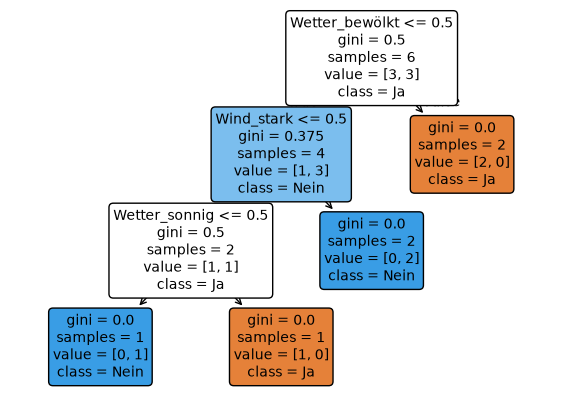

In [13]:
modell = DecisionTreeClassifier(criterion='gini', random_state=0)
modell.fit(X, y)

plt.figure(figsize=(7, 5))
plot_tree(modell, feature_names=list(X.columns), class_names=list(modell.classes_), filled=True, rounded=True)
plt.show()

So liest man das Bild:

- `Wetter_bewölkt <= 0.5` heißt *nicht bewölkt*. Nach links geht es, wenn die Bedingung erfüllt ist.
- `gini` ist die Unreinheit im Knoten, `samples` die Anzahl der Beispiele, `value` wie viele davon zu jeder Klasse
  gehören (Ja, Nein).

Die erste Frage ist dieselbe wie bei uns. Danach fragt sklearn nach dem Wind statt nach Regen. Beide Fragen waren gleich
gut, bei gleich guten Fragen entscheidet der Zufall (über `random_state` festgelegt). Der Baum sieht anders aus, trifft
aber für alle sechs Kombinationen dieselben Vorhersagen.

### Ein größeres Beispiel: die Titanic

Der Titanic-Datensatz enthält Angaben zu 891 Passagieren und ob sie den Untergang 1912 überlebt haben. Wir laden ihn
als CSV-Datei aus dem Internet. Einige Spalten:

- `sex`: Geschlecht, `age`: Alter, `pclass`: Klasse des Tickets (1, 2 oder 3)
- `sibsp`: Anzahl der Geschwister und Ehepartner an Bord (*siblings, spouses*)
- `parch`: Anzahl der Eltern und Kinder an Bord (*parents, children*)
- `embarked`: Hafen, in dem die Person an Bord ging: C = Cherbourg, Q = Queenstown, S = Southampton
- `survived`: 1 = überlebt, 0 = nicht überlebt

Zeilen mit fehlenden Werten lassen wir weg.

In [14]:
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv'
titanic = pd.read_csv(url)
merkmale = ['sex', 'pclass', 'age', 'sibsp', 'parch', 'embarked']
df = titanic[merkmale + ['survived']].dropna()
print(len(df), 'Passagiere, davon überlebt:', round(df['survived'].mean(), 3))
df.head()

712 Passagiere, davon überlebt: 0.404


,sex,pclass,age,sibsp,parch,embarked,survived
0,male,3,22.0,1,0,S,0
1,female,1,38.0,1,0,C,1
2,female,3,26.0,0,0,S,1
3,female,1,35.0,1,0,S,1
4,male,3,35.0,0,0,S,0


Um zu prüfen, wie gut ein Modell bei *neuen* Fällen ist, teilt man die Daten: Mit 80 % (**Trainingsdaten**) wird der
Baum gebaut, mit den übrigen 20 % (**Testdaten**) wird gemessen, wie oft er richtig liegt (**Genauigkeit**, accuracy).

In [15]:
from sklearn.model_selection import train_test_split

X = pd.get_dummies(df[merkmale])
y = df['survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

modell = DecisionTreeClassifier(random_state=0)
modell.fit(X_train, y_train)
print('Tiefe:', modell.get_depth(), ' Blätter:', modell.get_n_leaves())
print(f'Genauigkeit Training: {modell.score(X_train, y_train):.3f}')
print(f'Genauigkeit Test:     {modell.score(X_test, y_test):.3f}')

Tiefe: 17  Blätter: 149
Genauigkeit Training: 0.947
Genauigkeit Test:     0.783


#### Overfitting

Ohne Begrenzung wächst der Baum, bis fast jedes Blatt rein ist. Auf den Trainingsdaten liegt er dann fast immer
richtig, auf den Testdaten deutlich seltener: Er hat die Trainingsdaten auswendig gelernt, samt Zufällen, die sich
nicht verallgemeinern lassen. Das heißt **Overfitting**. Mit `max_depth` kann man die Tiefe begrenzen:

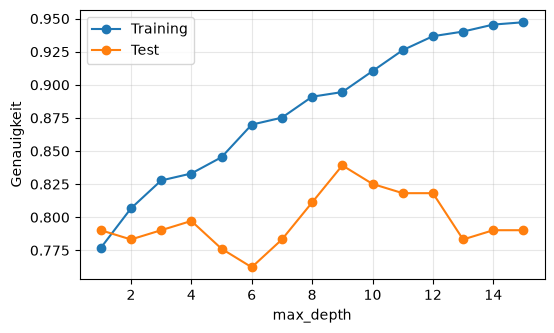

In [16]:
tiefen = list(range(1, 16))
train, test = [], []
for t in tiefen:
    m = DecisionTreeClassifier(max_depth=t, random_state=0).fit(X_train, y_train)
    train.append(m.score(X_train, y_train))
    test.append(m.score(X_test, y_test))

plt.figure(figsize=(6, 3.5))
plt.plot(tiefen, train, 'o-', label='Training')
plt.plot(tiefen, test, 'o-', label='Test')
plt.xlabel('max_depth')
plt.ylabel('Genauigkeit')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Die Trainingsgenauigkeit steigt mit der Tiefe immer weiter, die Testgenauigkeit nicht. Sie schwankt aber stark, weil
die Testdaten nur 143 Passagiere sind: Ein einziger Passagier mehr oder weniger richtig macht schon 0.7 Prozentpunkte
aus. Mit einer anderen zufälligen Aufteilung sähe die Kurve anders aus.

Zuverlässiger ist die **Kreuzvalidierung**: Man teilt die Daten in 5 Teile, nimmt jeden Teil einmal als Testdaten und
die anderen vier als Trainingsdaten, und mittelt die 5 Ergebnisse.

In [17]:
from sklearn.model_selection import cross_val_score

for t in [1, 2, 3, 4, 6, 8, 12, None]:
    werte = cross_val_score(DecisionTreeClassifier(max_depth=t, random_state=0), X, y, cv=5)
    print(f'max_depth {str(t):5} Mittelwert {werte.mean():.3f}   einzeln', werte.round(2))

max_depth 1     Mittelwert 0.779   einzeln [0.78 0.82 0.77 0.73 0.79]
max_depth 2     Mittelwert 0.791   einzeln [0.76 0.8  0.82 0.77 0.8 ]
max_depth 3     Mittelwert 0.764   einzeln [0.71 0.8  0.77 0.75 0.78]
max_depth 4     Mittelwert 0.784   einzeln [0.71 0.83 0.8  0.77 0.82]
max_depth 6     Mittelwert 0.791   einzeln [0.73 0.83 0.77 0.78 0.84]
max_depth 8     Mittelwert 0.781   einzeln [0.71 0.82 0.73 0.79 0.86]
max_depth 12    Mittelwert 0.778   einzeln [0.69 0.82 0.75 0.79 0.85]
max_depth None  Mittelwert 0.774   einzeln [0.69 0.81 0.75 0.79 0.84]


Alle Tiefen liegen zwischen 0.76 und 0.79, die Unterschiede sind kleiner als die Schwankung zwischen den einzelnen
Teilen.
Ein großer Baum ist also nicht besser als ein kleiner. Dann nimmt man den kleinen: Er ist schneller und man kann ihn
lesen.

Zum Vergleich: Wer einfach immer *nicht überlebt* vorhersagt, liegt bei knapp 60 % richtig.

Test: 0.783


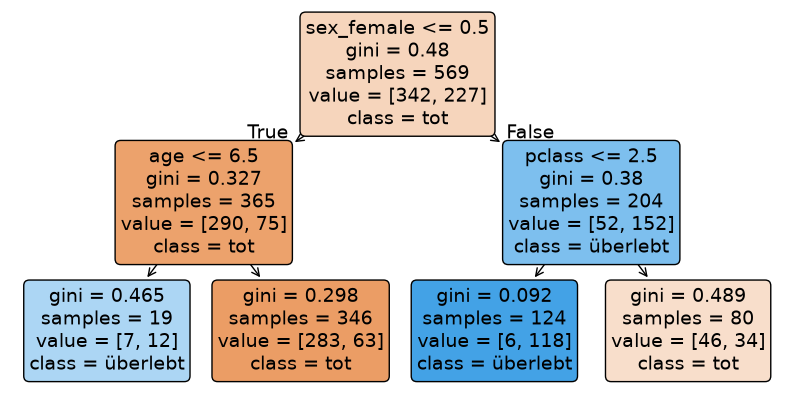

In [18]:
klein = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)
print(f'Test: {klein.score(X_test, y_test):.3f}')
plt.figure(figsize=(10, 5))
plot_tree(klein, feature_names=list(X.columns), class_names=['tot', 'überlebt'], filled=True, rounded=True)
plt.show()

Die erste Frage ist das Geschlecht: Frauen haben weit häufiger überlebt als Männer (*Frauen und Kinder zuerst*).
Danach kommt bei den Männern das Alter (Jungen bis 6 Jahre haben eher überlebt), bei den Frauen die Ticketklasse (in der
3. Klasse hat weniger als die Hälfte überlebt).

#### Hyperparameter

Einstellungen, die man vor dem Training festlegt, heißen **Hyperparameter**. Gegen Overfitting helfen bei
Entscheidungsbäumen vor allem diese:

| Parameter | Bedeutung | übliche Werte zum Ausprobieren |
|---|---|---|
| `max_depth` | größte Tiefe des Baums | `None` (keine Grenze), 3 bis 15 |
| `min_samples_split` | so viele Beispiele muss ein Knoten mindestens haben, damit er geteilt wird | 2, 5, 10, 20 |
| `min_samples_leaf` | so viele Beispiele muss jedes Blatt mindestens haben | 1, 2, 4, 10 |
| `max_leaf_nodes` | höchstens so viele Blätter | `None`, 5, 10, 20 |

### Vor- und Nachteile

- Entscheidungsbäume sind **verständlich**: Man kann nachvollziehen, warum das Modell etwas vorhersagt. Bei neuronalen
  Netzen geht das kaum.
- Sie brauchen wenig Vorbereitung der Daten, Merkmale mit Texten und Zahlen lassen sich mischen.
- Sie neigen zu **Overfitting** und sind **instabil**: Ein paar andere Trainingsbeispiele können einen ganz anderen
  Baum ergeben.

Ein **Random Forest** (Zufallswald) baut deshalb viele Bäume, jeden auf einer zufälligen Auswahl der Beispiele und
Merkmale, und lässt sie abstimmen. Das ist meist genauer und stabiler als ein einzelner Baum, aber nicht mehr so leicht
zu lesen.

In [19]:
from sklearn.ensemble import RandomForestClassifier

wald = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=0)
werte = cross_val_score(wald, X, y, cv=5)
print(f'Random Forest: Mittelwert {werte.mean():.3f}', werte.round(2))

Random Forest: Mittelwert 0.796 [0.74 0.84 0.77 0.79 0.85]


Hier ist der Gewinn gegenüber einem einzelnen Baum klein. Bei Datensätzen mit mehr Merkmalen ist der Unterschied
oft größer.

### Zusammenfassung

- Ein **Entscheidungsbaum** sagt eine Klasse mit einer Folge von Ja/Nein-Fragen voraus.
- Die **Gini Impurity** $1 - \sum p_i^2$ misst, wie gemischt eine Gruppe ist: 0 heißt rein, bei zwei Klassen ist 0.5
  das Maximum.
- Gebaut wird der Baum **gierig und rekursiv**: In jedem Knoten die Frage mit dem kleinsten **gewichteten Gini**
  wählen, bis die Gruppen rein sind. Bei Zahlen sind die Schwellen die Mitten zwischen benachbarten Werten.
- Ob ein Modell taugt, misst man auf **Testdaten**, die beim Training nicht benutzt wurden, oder mit
  **Kreuzvalidierung**.
- Ein zu großer Baum lernt die Trainingsdaten auswendig (**Overfitting**). Hyperparameter wie `max_depth` begrenzen
  ihn.